# 02 · Baseline: Cellpose-SAM (off the shelf)

Week 4 of `notes/plan.md`: baseline performance.

**Task: total cell count per image.** We count cells without telling Live from Dead, because most other cell datasets don't label viability. Live/Dead is a later extension: the colour rule for it is kept in `cellcount.cellpose_zs`.

**Baseline model: Cellpose-SAM** (`cpsam_v2`), a published cell-segmentation model used **as downloaded**. Its weights are never trained on our images. Three numbers are chosen on **training images only**, each to minimize total-count MAE:
- the two mask thresholds Cellpose exposes, `cellprob_threshold` and `flow_threshold`, from a 5 × 3 grid
- a minimum cell area that drops debris and fragments

Two sanity references use no image content at all: **B0** predicts the training-set mean count, and **B1** predicts the image's session mean (the "recognize the session" shortcut).

Two test levels: the **random split** (`split == "test"` in `splits/splits.csv`, 75 images) and **leave-one-session-out** (choose the three numbers on 4 sessions, test on the 5th). Results go to `outputs/results/baseline_cellpose.csv`, figures to `outputs/figures/baseline_cellpose/`.

YOLO is not run here; it is trained on Colab next. Needs the modeling extras: `pip install -e ".[dev,model]"`. The Cellpose network outputs and masks are cached in `outputs/cache/cellpose/`, so re-runs skip the model.

In [1]:
# --- Bootstrap (identical in every notebook). Does nothing when run locally. ---
# On Colab: mounts Google Drive (data/ and outputs/ live there), clones or updates the repo,
# and installs the `cellcount` utils. Secrets: add ROBOFLOW_EXPORT_URL (and GH_TOKEN if the
# repo is private) under the key icon in the left sidebar, with notebook access enabled.
import os, subprocess, sys

REPO_URL = "https://github.com/Erdos-Projects/fall-2026-automated-cell-counting.git"
BRANCH = "main"  # set to a feature branch to try unmerged work

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive, userdata

    drive.mount("/content/drive")
    repo = "/content/fall-2026-automated-cell-counting"
    try:
        url = REPO_URL.replace("https://", f"https://{userdata.get('GH_TOKEN')}@")
    except Exception:
        url = REPO_URL
    cmd = ["git", "-C", repo, "pull", "-q"] if os.path.exists(repo) else ["git", "clone", "-q", "-b", BRANCH, url, repo]
    if subprocess.run(cmd).returncode != 0:
        raise RuntimeError("git clone/pull failed: check BRANCH and the GH_TOKEN secret")
    # [model] adds cellpose (torch is preinstalled on Colab)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", f"{repo}[model]"], check=True)
    sys.path.insert(0, f"{repo}/src")  # import without restarting the runtime
    os.chdir(repo)

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from cellcount import baselines, cellpose_zs, viz
from cellcount.config import get_paths
from cellcount.data import RAW_DIRNAME, load_coco
from cellcount.eda import count_bins, image_stats
from cellcount.metrics import count_metrics_by, match_boxes, per_image_counts, total_count_metrics
from cellcount.splits import leave_one_source_out, load_splits

sns.set_theme(style="whitegrid", context="notebook")
paths = get_paths()
FIG = paths.outputs / "figures" / "baseline_cellpose"
FIG.mkdir(parents=True, exist_ok=True)
(paths.outputs / "results").mkdir(exist_ok=True)
CACHE = paths.outputs / "cache" / "cellpose"

images, boxes = load_coco(paths.data / RAW_DIRNAME)
split_df = load_splits(paths.root / "splits" / "splits.csv")
truth = per_image_counts(boxes, images["uid"]).rename(columns={"live": "live_true", "dead": "dead_true"})
blur = image_stats(images)[["uid", "blur"]]
df = (images[["uid", "path", "width", "height", "source"]]
      .merge(split_df[["uid", "split"]], on="uid")
      .merge(truth, on="uid")
      .merge(blur, on="uid"))
df["total_true"] = df["live_true"] + df["dead_true"]
df["count_bin"] = count_bins(df["total_true"])
df["blur_bin"] = pd.qcut(df["blur"], 4, labels=["blurriest 25%", "2nd", "3rd", "sharpest 25%"])
train, valid, test = (df[df["split"] == s] for s in ("train", "valid", "test"))
print(df["split"].value_counts().to_dict(), "| sessions:", df["source"].nunique(), "| labelled cells:", len(boxes))

image stats:   0%|          | 0/500 [00:00<?, ?it/s]

image stats:   2%|▏         | 8/500 [00:00<00:06, 73.04it/s]

image stats:   4%|▎         | 18/500 [00:00<00:05, 85.22it/s]

image stats:   6%|▌         | 28/500 [00:00<00:05, 87.56it/s]

image stats:   7%|▋         | 37/500 [00:00<00:05, 88.00it/s]

...

image stats:  94%|█████████▍| 471/500 [00:05<00:00, 91.88it/s]

image stats:  96%|█████████▌| 481/500 [00:05<00:00, 92.45it/s]

image stats:  98%|█████████▊| 491/500 [00:05<00:00, 92.47it/s]

image stats: 100%|██████████| 500/500 [00:05<00:00, 90.29it/s]

{'train': 351, 'test': 75, 'valid': 74} | sessions: 5 | labelled cells: 26715


In [3]:
results = []   # one row per method x test level x fold
preds = {}     # per-image predictions on the random-split test, for the figures


def cell_detection(pred_boxes, uids, iou):
    """Class-agnostic precision and recall: each predicted box matches at most one labelled box."""
    m = match_boxes(pred_boxes[pred_boxes["uid"].isin(uids)], boxes[boxes["uid"].isin(uids)],
                    iou=iou, by_class=False)[["tp", "fp", "fn"]].sum()
    return {"precision": m["tp"] / (m["tp"] + m["fp"]), "recall": m["tp"] / (m["tp"] + m["fn"])}


def evaluate(method, level, fold, counted, pred_boxes=None):
    """Score one set of per-image predictions (``total_pred``) and store the row in ``results``."""
    row = {"method": method, "level": level, "fold": fold, **total_count_metrics(counted)}
    if pred_boxes is not None:
        for iou in (0.5, 0.3):
            row.update({f"{k}_iou{iou}": v for k, v in cell_detection(pred_boxes, counted["uid"], iou).items()})
    results.append(row)
    return row

## B0, B1: reference baselines

On the random split, B1 shows how much the session alone explains. Under leave-one-session-out the held-out session is unseen, so B1 falls back to B0.

In [4]:
def with_total(pred):
    return pred.assign(total_pred=pred["live_pred"] + pred["dead_pred"])


for name, fn in [("B0 mean", baselines.predict_mean), ("B1 session mean", baselines.predict_session_mean)]:
    preds[name] = with_total(fn(train, test))
    evaluate(name, "random split", "test", preds[name])
    loso = pd.concat([with_total(fn(tr, te)) for _, tr, te in leave_one_source_out(df)])
    evaluate(name, "leave-one-session-out", "pooled", loso)
pd.DataFrame(results).set_index(["method", "level"])[["mae_total", "r2_total", "within_10pct"]].round(3)

mae_total  r2_total  within_10pct
method          level                                                   
B0 mean         random split              12.724    -0.006         0.240
                leave-one-session-out     14.629    -0.403         0.204
B1 session mean random split               6.854     0.705         0.453
                leave-one-session-out     14.629    -0.403         0.204

## B3: Cellpose-SAM, choosing the thresholds on training images

The network runs once per image (outputs cached), and masks are made for every threshold pair in `cellpose_zs.THRESHOLD_GRID`. For each pair, the minimum area is fitted on the training images; the pair with the lowest training MAE wins. Validation MAE is shown for information only and isn't used to choose.

In [5]:
masks_by_setting = {(cp, fl): cellpose_zs.segment(df, CACHE, cellprob_threshold=cp, flow_threshold=fl)
                    for cp, fl in cellpose_zs.threshold_grid()}
cells_by_setting = {k: cellpose_zs.cell_areas(m) for k, m in masks_by_setting.items()}

grid = cellpose_zs.tune(cells_by_setting, train).rename(columns={"mae": "train_mae"})
grid["valid_mae"] = [
    (cellpose_zs.count_cells(cells_by_setting[(r.cellprob_threshold, r.flow_threshold)], valid["uid"], r.min_area)
     - valid.set_index("uid")["total_true"]).abs().mean()
    for r in grid.itertuples()
]
best = grid.iloc[0]
setting = (best["cellprob_threshold"], best["flow_threshold"])
print(f"chosen on train: cellprob_threshold = {setting[0]}, flow_threshold = {setting[1]}, min area = {best['min_area']:.0f} px")
grid.round(2)

cellpose cellprob_threshold=0.0_flow_threshold=0.4:   0%|          | 0/500 [00:00<?, ?it/s]

cellpose cellprob_threshold=0.0_flow_threshold=0.4:  27%|██▋       | 137/500 [00:00<00:00, 1363.55it/s]

cellpose cellprob_threshold=0.0_flow_threshold=0.4:  57%|█████▋    | 287/500 [00:00<00:00, 1436.78it/s]

cellpose cellprob_threshold=0.0_flow_threshold=0.4:  87%|████████▋ | 435/500 [00:00<00:00, 1455.60it/s]

cellpose cellprob_threshold=0.0_flow_threshold=0.4: 100%|██████████| 500/500 [00:00<00:00, 1448.52it/s]

...

cellpose cellprob_threshold=-8.0_flow_threshold=1.0:  71%|███████   | 355/500 [00:00<00:00, 1184.86it/s]

cellpose cellprob_threshold=-8.0_flow_threshold=1.0:  95%|█████████▍| 474/500 [00:00<00:00, 1174.99it/s]

cellpose cellprob_threshold=-8.0_flow_threshold=1.0: 100%|██████████| 500/500 [00:00<00:00, 1171.26it/s]

chosen on train: cellprob_threshold = -4.0, flow_threshold = 1.0, min area = 400 px


,cellprob_threshold,flow_threshold,min_area,train_mae,valid_mae
0,-4.0,1.0,400.0,5.93,7.04
1,-6.0,1.0,400.0,6.01,7.01
2,-8.0,1.0,400.0,6.02,7.01
3,-2.0,1.0,0.0,11.13,13.26
4,-2.0,0.7,0.0,14.66,17.93
5,-4.0,0.7,0.0,17.42,20.85
6,-6.0,0.7,0.0,18.96,22.69
7,-8.0,0.7,0.0,18.97,22.69
8,-2.0,0.4,0.0,27.48,31.53
9,0.0,1.0,0.0,29.68,33.82


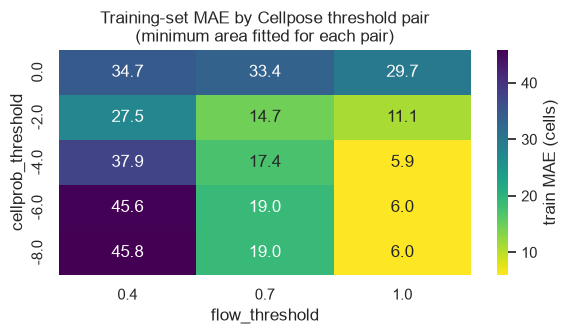

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5))
pivot = grid.pivot(index="cellprob_threshold", columns="flow_threshold", values="train_mae").sort_index(ascending=False)
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="viridis_r", ax=ax, cbar_kws={"label": "train MAE (cells)"})
ax.set(title="Training-set MAE by Cellpose threshold pair\n(minimum area fitted for each pair)")
fig.tight_layout()
fig.savefig(FIG / "00_threshold_grid.png", dpi=150)

## B2 and B3: test results

**B2 (Cellpose defaults)** is Cellpose exactly as shipped: its default thresholds (0, 0.4) and no area filter.

In [7]:
def cellpose_counts(frame, key, min_area):
    counts = cellpose_zs.count_cells(cells_by_setting[key], frame["uid"], min_area)
    return frame.assign(total_pred=frame["uid"].map(counts).to_numpy())


for name, key, min_area in [("B2 Cellpose-SAM (defaults)", (0.0, 0.4), 0), ("B3 Cellpose-SAM (tuned on train)", setting, best["min_area"])]:
    pred_boxes = cellpose_zs.mask_boxes({u: masks_by_setting[key][u] for u in test["uid"]}, min_area)
    preds[name] = cellpose_counts(test, key, min_area)
    evaluate(name, "random split", "test", preds[name], pred_boxes)
cp_boxes = pred_boxes

# Leave one session out: the thresholds and the minimum area are chosen again on the 4 other sessions.
loso, folds = [], []
for source, tr, te in leave_one_source_out(df):
    g = cellpose_zs.tune(cells_by_setting, tr).iloc[0]
    key = (g["cellprob_threshold"], g["flow_threshold"])
    counted = cellpose_counts(te, key, g["min_area"])
    fold_boxes = cellpose_zs.mask_boxes({u: masks_by_setting[key][u] for u in te["uid"]}, g["min_area"])
    evaluate("B3 Cellpose-SAM (tuned on train)", "leave-one-session-out", source, counted, fold_boxes)
    folds.append({"held-out session": source, "cellprob_threshold": key[0], "flow_threshold": key[1], "min_area": g["min_area"]})
    loso.append((counted, fold_boxes))
evaluate("B3 Cellpose-SAM (tuned on train)", "leave-one-session-out", "pooled",
         pd.concat([c for c, _ in loso]), pd.concat([b for _, b in loso]))
pd.DataFrame(folds)

,held-out session,cellprob_threshold,flow_threshold,min_area
0,2022_12_7_1_A,-4.0,1.0,400.0
1,2022_12_7_1_B,-4.0,1.0,300.0
2,2022_12_7_2_A,-4.0,1.0,400.0
3,2022_12_7_2_B,-4.0,1.0,400.0
4,2022_12_7_3_A,-4.0,1.0,400.0


## Results table

In [8]:
res = pd.DataFrame(results)
res.to_csv(paths.outputs / "results" / "baseline_cellpose.csv", index=False)

cols = ["mae_total", "bias_total", "rmse_total", "rel_err_total", "within_10pct", "r2_total",
        "precision_iou0.5", "recall_iou0.5", "precision_iou0.3", "recall_iou0.3"]
summary = res[res["fold"].isin(["test", "pooled"])].set_index(["level", "method"])[cols]
summary.round(3)

mae_total  bias_total  \
level                 method                                                    
random split          B0 mean                              12.724       1.121   
leave-one-session-out B0 mean                              14.629      -0.000   
random split          B1 session mean                       6.854       1.702   
leave-one-session-out B1 session mean                      14.629      -0.000   
random split          B2 Cellpose-SAM (defaults)           34.813     -34.627   
                      B3 Cellpose-SAM (tuned on train)      5.600      -0.640   
leave-one-session-out B3 Cellpose-SAM (tuned on train)      6.280      -1.064   

                                                        rmse_total  \
level                 method                                         
random split          B0 mean                               14.854   
leave-one-session-out B0 mean                               17.105   
random split          B1 session mean                        8.050   
leave-one-session-out B1 session mean                       17.105   
random split          B2 Cellpose-SAM (defaults)            39.761   
                      B3 Cellpose-SAM (tuned on train)       7.499   
leave-one-session-out B3 Cellpose-SAM (tuned on train)       9.332   

                                                        rel_err_total  \
level                 method                                            
random split          B0 mean                                   0.278   
leave-one-session-out B0 mean                                   0.305   
random split          B1 session mean                           0.143   
leave-one-session-out B1 session mean                           0.305   
random split          B2 Cellpose-SAM (defaults)                0.664   
                      B3 Cellpose-SAM (tuned on train)          0.112   
leave-one-session-out B3 Cellpose-SAM (tuned on train)          0.120   

                                                        within_10pct  \
level                 method                                           
random split          B0 mean                                  0.240   
leave-one-session-out B0 mean                                  0.204   
random split          B1 session mean                          0.453   
leave-one-session-out B1 session mean                          0.204   
random split          B2 Cellpose-SAM (defaults)               0.093   
                      B3 Cellpose-SAM (tuned on train)         0.587   
leave-one-session-out B3 Cellpose-SAM (tuned on train)         0.616   

                                                        r2_total  \
level                 method                                       
random split          B0 mean                             -0.006   
leave-one-session-out B0 mean                             -0.403   
random split          B1 session mean                      0.705   
leave-one-session-out B1 session mean                     -0.403   
random split          B2 Cellpose-SAM (defaults)          -6.206   
                      B3 Cellpose-SAM (tuned on train)     0.744   
leave-one-session-out B3 Cellpose-SAM (tuned on train)     0.583   

                                                        precision_iou0.5  \
level                 method                                               
random split          B0 mean                                        NaN   
leave-one-session-out B0 mean                                        NaN   
random split          B1 session mean                                NaN   
leave-one-session-out B1 session mean                                NaN   
random split          B2 Cellpose-SAM (defaults)                   0.946   
                      B3 Cellpose-SAM (tuned on train)             0.646   
leave-one-session-out B3 Cellpose-SAM (tuned on train)             0.640   

                                                        recall_iou0.5  \
level            

In [9]:
# Leave-one-session-out, one row per held-out session
res[(res["level"] == "leave-one-session-out") & (res["fold"] != "pooled")].set_index(["method", "fold"])[
    ["mae_total", "bias_total", "within_10pct", "r2_total"]].round(2)

mae_total  bias_total  \
method                           fold                                   
B3 Cellpose-SAM (tuned on train) 2022_12_7_1_A       5.63       -0.87   
                                 2022_12_7_1_B       7.18        5.12   
                                 2022_12_7_2_A       5.72       -2.70   
                                 2022_12_7_2_B       3.73       -0.09   
                                 2022_12_7_3_A       9.14       -6.78   

                                                within_10pct  r2_total  
method                           fold                                   
B3 Cellpose-SAM (tuned on train) 2022_12_7_1_A          0.66      0.04  
                                 2022_12_7_1_B          0.59     -0.19  
                                 2022_12_7_2_A          0.52     -1.03  
                                 2022_12_7_2_B          0.71      0.60  
                                 2022_12_7_3_A          0.60     -1.90

## Diagnostics (random-split test)

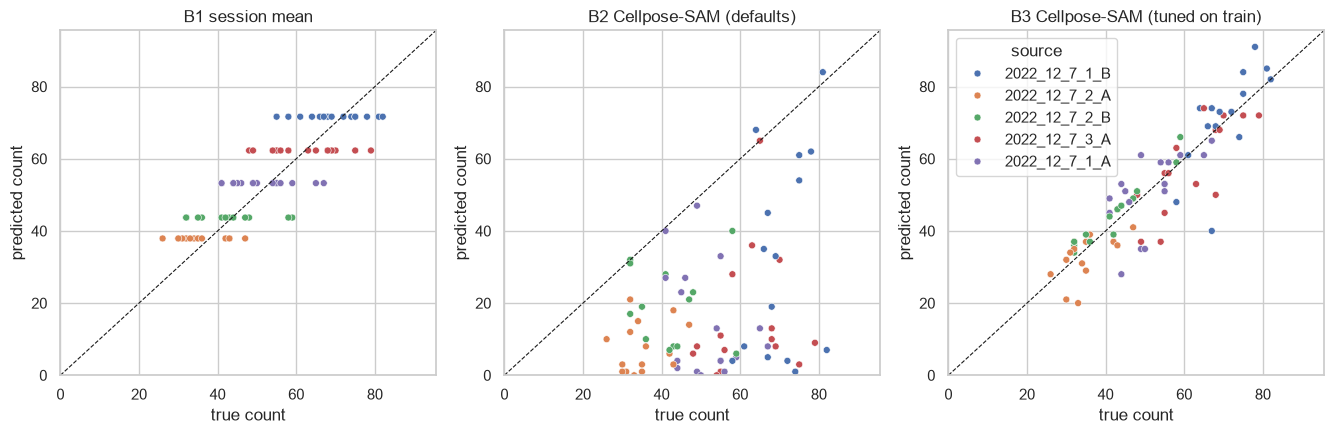

In [10]:
B3 = "B3 Cellpose-SAM (tuned on train)"
shown = ["B1 session mean", "B2 Cellpose-SAM (defaults)", B3]
fig, axes = plt.subplots(1, len(shown), figsize=(4.5 * len(shown), 4.5))
lim = [0, max(test["total_true"].max(), max(preds[m]["total_pred"].max() for m in shown)) * 1.05]
for ax, m in zip(axes, shown):
    p = preds[m]
    sns.scatterplot(x=p["total_true"], y=p["total_pred"], hue=p["source"], ax=ax, s=25, legend=(m == B3))
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set(xlim=lim, ylim=lim, xlabel="true count", ylabel="predicted count", title=m)
fig.tight_layout()
fig.savefig(FIG / "01_pred_vs_true.png", dpi=150)

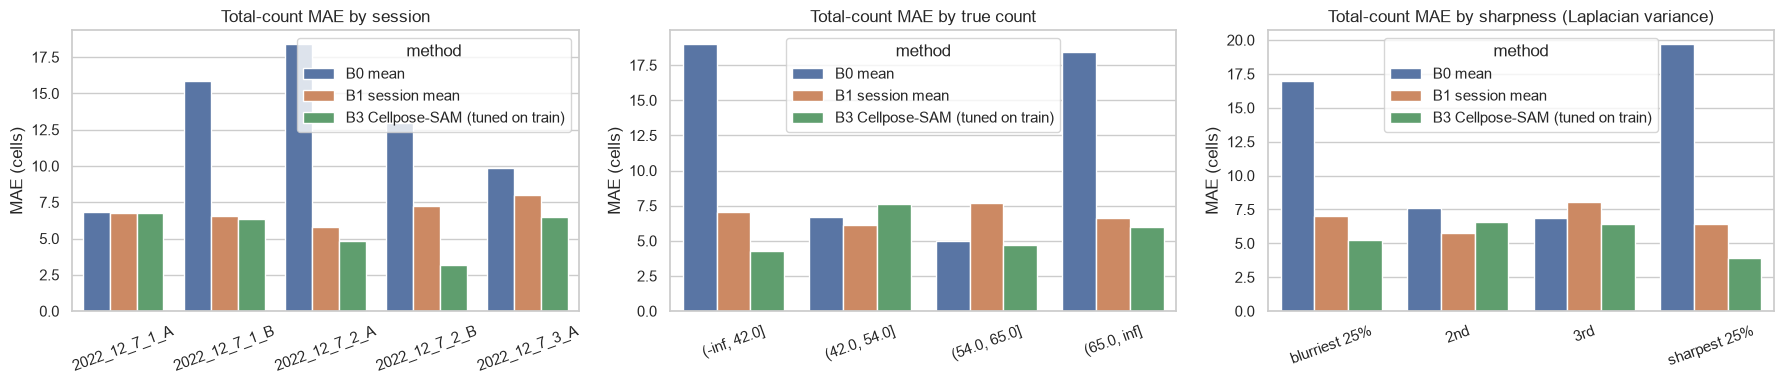

In [11]:
by = []
for m in ["B0 mean", "B1 session mean", B3]:
    p = preds[m]
    for col, name in [("source", "session"), ("count_bin", "true count"), ("blur_bin", "sharpness (Laplacian variance)")]:
        g = count_metrics_by(p, p[col], total_count_metrics)[["mae_total"]].reset_index(names="group")
        by.append(g.assign(method=m, by=name, group=g["group"].astype(str)))
by = pd.concat(by)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, name in zip(axes, by["by"].unique()):
    sns.barplot(data=by[by["by"] == name], x="group", y="mae_total", hue="method", ax=ax)
    ax.set(title=f"Total-count MAE by {name}", xlabel="", ylabel="MAE (cells)")
    ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(FIG / "02_mae_by_session_count_blur.png", dpi=150)

Spearman correlation of |error| with sharpness: -0.12


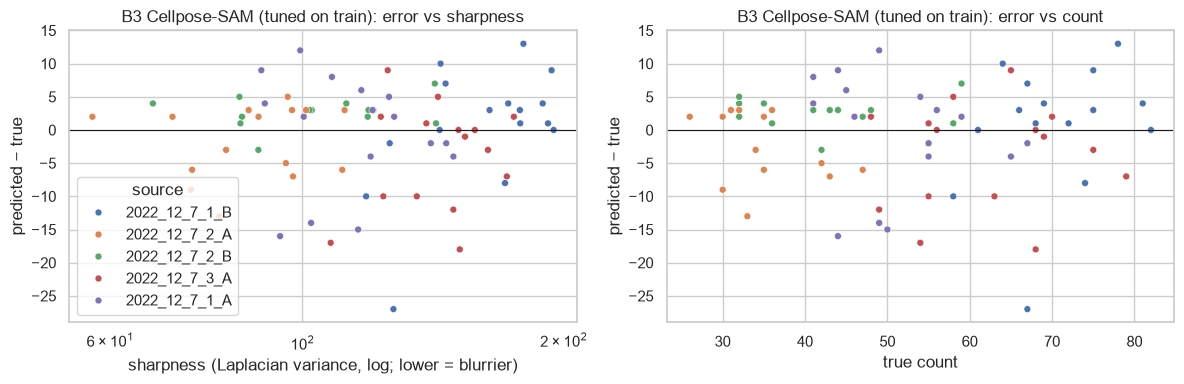

In [12]:
p = preds[B3].assign(err=lambda d: d["total_pred"] - d["total_true"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=p, x="blur", y="err", hue="source", ax=axes[0], s=25)
axes[0].set(xscale="log", xlabel="sharpness (Laplacian variance, log; lower = blurrier)", ylabel="predicted − true",
            title=f"{B3}: error vs sharpness")
sns.scatterplot(data=p, x="total_true", y="err", hue="source", ax=axes[1], s=25, legend=False)
axes[1].set(xlabel="true count", ylabel="predicted − true", title=f"{B3}: error vs count")
for ax in axes:
    ax.axhline(0, color="k", lw=0.8)
fig.tight_layout()
fig.savefig(FIG / "03_error_vs_blur_and_count.png", dpi=150)
print(f"Spearman correlation of |error| with sharpness: {p['err'].abs().corr(p['blur'], method='spearman'):.2f}")

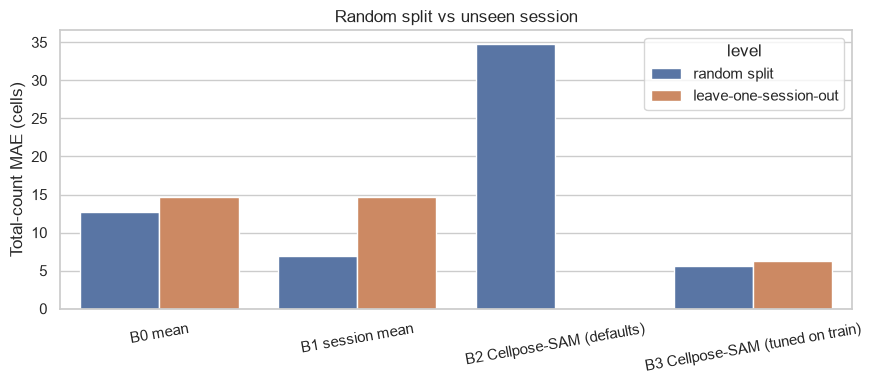

In [13]:
lv = res[res["fold"].isin(["test", "pooled"])]
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=lv, x="method", y="mae_total", hue="level", ax=ax)
ax.set(title="Random split vs unseen session", xlabel="", ylabel="Total-count MAE (cells)")
ax.tick_params(axis="x", rotation=10)
fig.tight_layout()
fig.savefig(FIG / "04_random_vs_loso.png", dpi=150)

**Worst test images** (largest total-count error). Yellow: labelled boxes. Cyan: Cellpose cells.

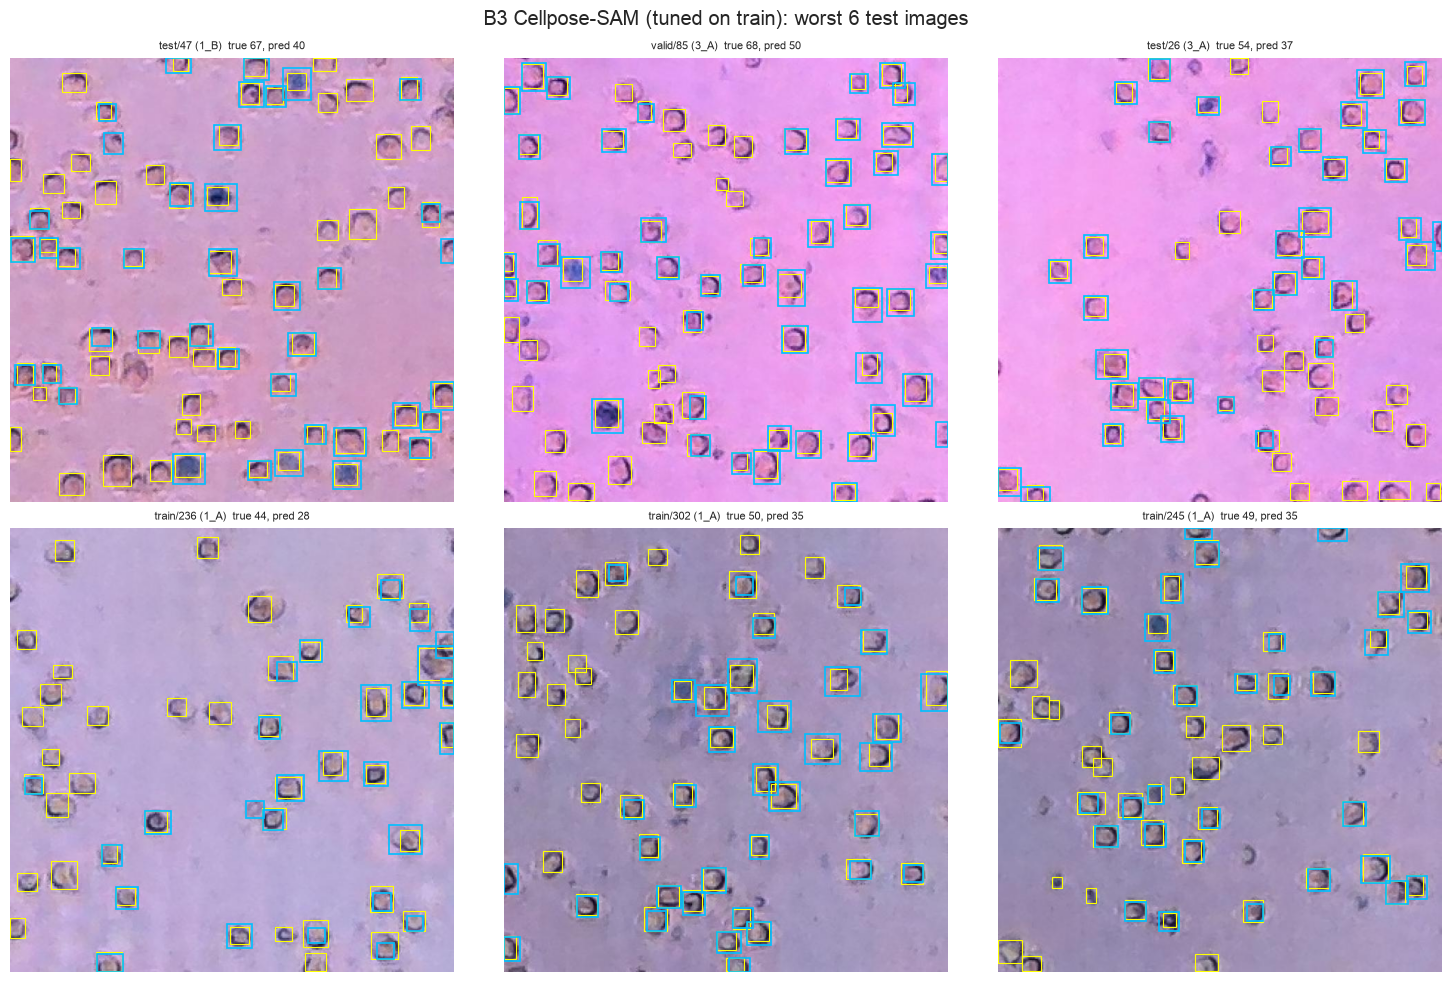

In [14]:
by_uid = df.set_index("uid", drop=False)
worst = p.reindex(p["err"].abs().sort_values(ascending=False).index).head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, r in zip(axes.flat, worst.itertuples()):
    viz.show_prediction(by_uid.loc[r.uid], boxes, cp_boxes, ax=ax,
                        title=f"{r.uid} ({r.source[-3:]})  true {r.total_true}, pred {r.total_pred}")
fig.suptitle(f"{B3}: worst 6 test images")
fig.tight_layout()
fig.savefig(FIG / "05_worst_cellpose.png", dpi=120)

**Worst test images with Cellpose's default settings** (`cellprob_threshold = 0`, `flow_threshold = 0.4`, no area filter). Yellow: labelled boxes. Cyan: Cellpose cells.

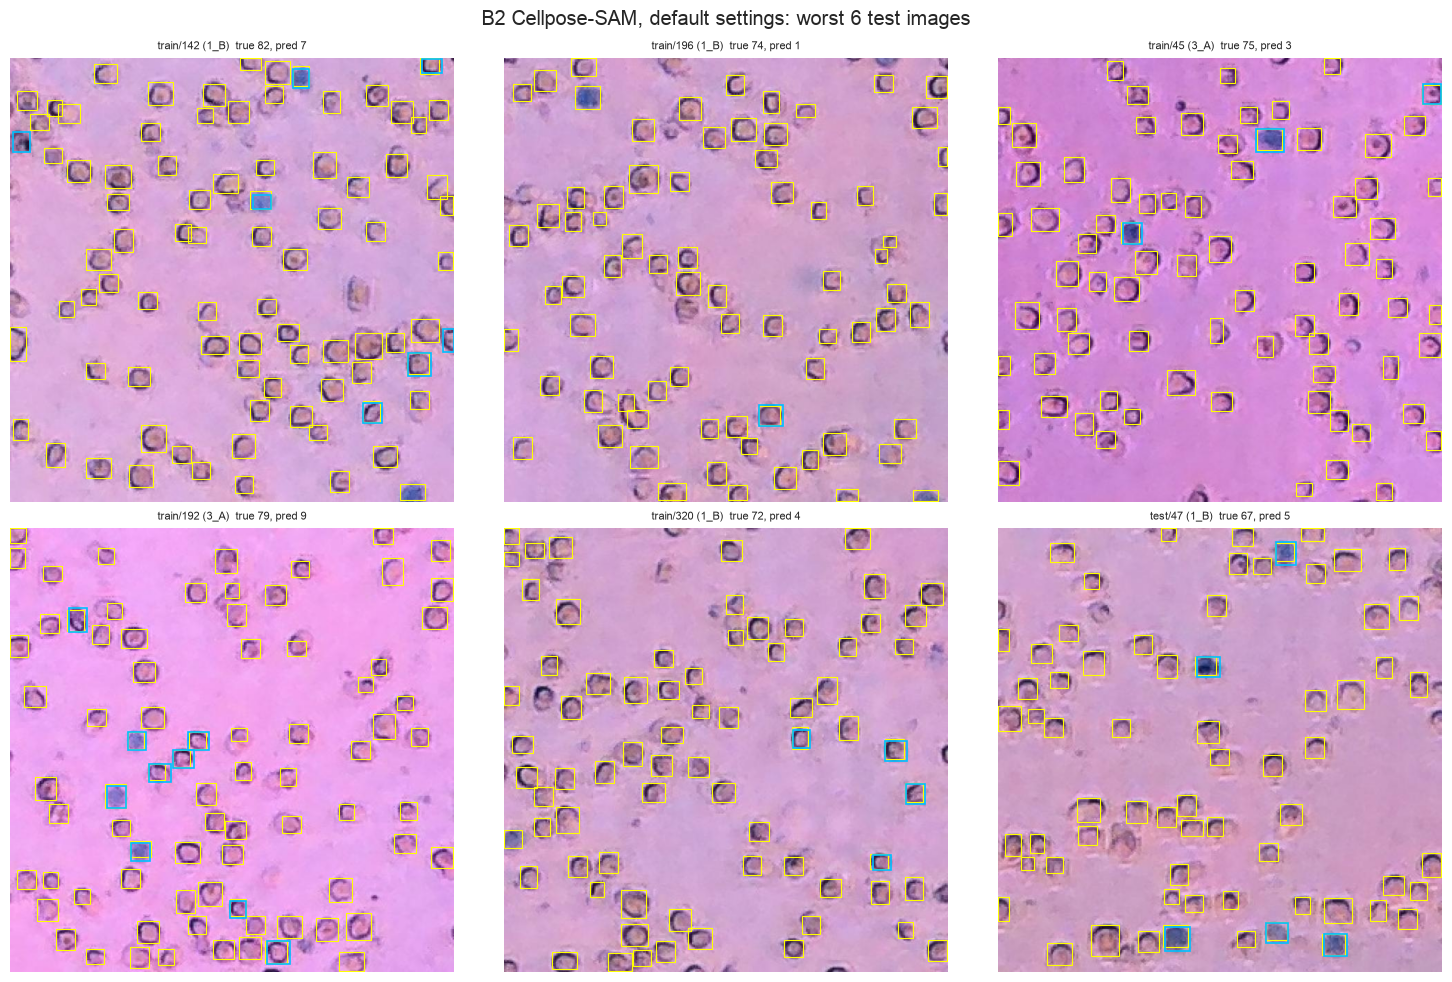

In [15]:
DEFAULT = (0.0, 0.4)
default_boxes = cellpose_zs.mask_boxes({u: masks_by_setting[DEFAULT][u] for u in test["uid"]})
p_def = preds["B2 Cellpose-SAM (defaults)"].assign(err=lambda d: d["total_pred"] - d["total_true"])
worst = p_def.reindex(p_def["err"].abs().sort_values(ascending=False).index).head(6)
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, r in zip(axes.flat, worst.itertuples()):
    viz.show_prediction(by_uid.loc[r.uid], boxes, default_boxes, ax=ax,
                        title=f"{r.uid} ({r.source[-3:]})  true {r.total_true}, pred {r.total_pred}")
fig.suptitle("B2 Cellpose-SAM, default settings: worst 6 test images")
fig.tight_layout()
fig.savefig(FIG / "06_worst_cellpose_default.png", dpi=120)

**What each threshold does**, on the worst image above: lowering `cellprob_threshold` lets fainter pixels into cells; raising `flow_threshold` keeps outlines whose shape is less clean. No area filter here, so every outline is shown.

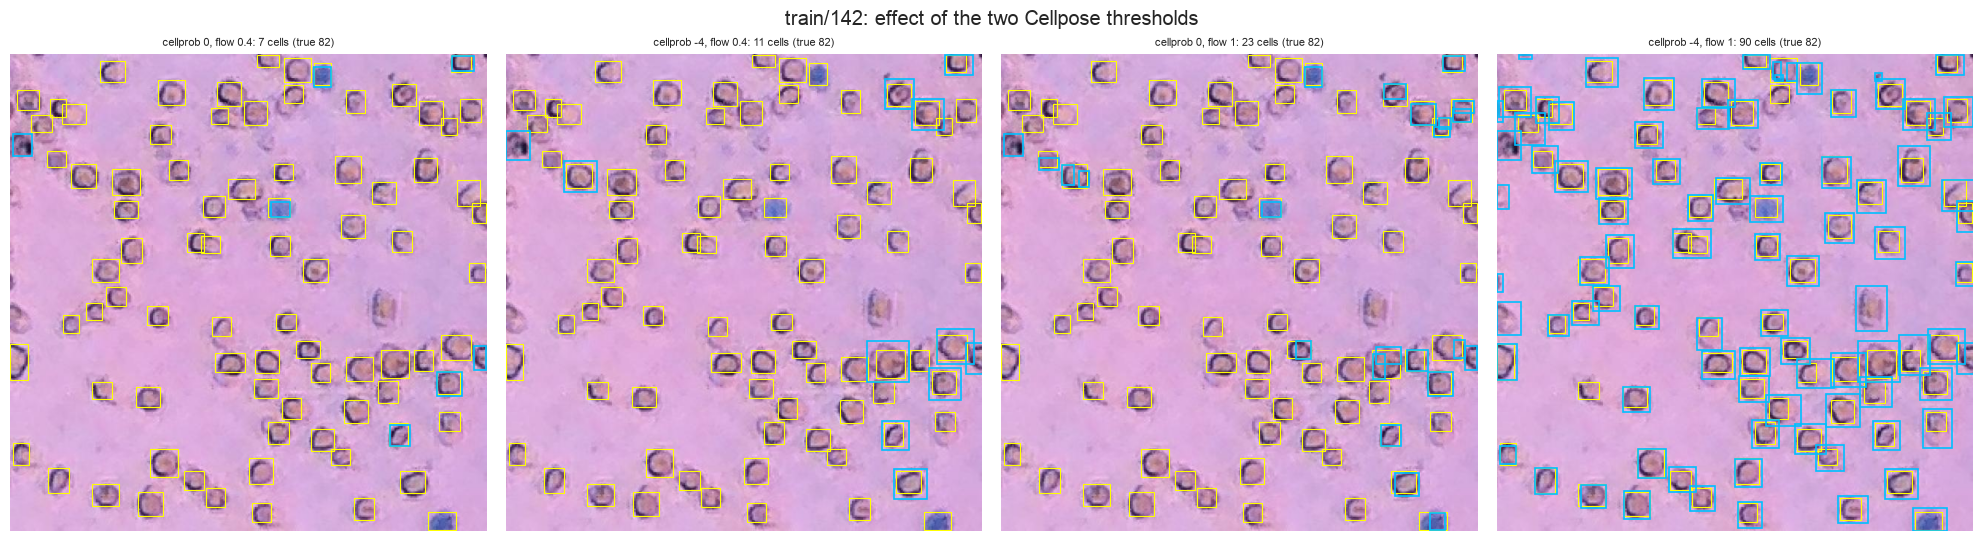

In [16]:
uid = worst.iloc[0]["uid"]
settings = [(0.0, 0.4), (-4.0, 0.4), (0.0, 1.0), (-4.0, 1.0)]
fig, axes = plt.subplots(1, 4, figsize=(20, 5.5))
for ax, (cp, fl) in zip(axes, settings):
    b = cellpose_zs.mask_boxes({uid: masks_by_setting[(cp, fl)][uid]})
    viz.show_prediction(by_uid.loc[uid], boxes, b, ax=ax,
                        title=f"cellprob {cp:g}, flow {fl:g}: {len(b)} cells (true {by_uid.loc[uid, 'total_true']})")
fig.suptitle(f"{uid}: effect of the two Cellpose thresholds")
fig.tight_layout()
fig.savefig(FIG / "07_threshold_effect.png", dpi=110)

## Inference time per image

Network plus mask building, on this machine's GPU, excluding model loading. Counting by hand takes on the order of a minute per image.

In [17]:
import shutil
import tempfile
from pathlib import Path

sample = test.head(20)
tmp = Path(tempfile.mkdtemp())
kw = dict(cellprob_threshold=setting[0], flow_threshold=setting[1])
cellpose_zs.segment(sample.head(1), tmp, **kw)  # load the model once
t0 = time.perf_counter()
cellpose_zs.segment(sample.iloc[1:], tmp, **kw)
cp_sec = (time.perf_counter() - t0) / (len(sample) - 1)
shutil.rmtree(tmp)
print(f"Cellpose-SAM: {cp_sec:.2f} s per image on {cellpose_zs._device()}")

cellpose cellprob_threshold=-4.0_flow_threshold=1.0:   0%|          | 0/1 [00:00<?, ?it/s]

cellpose cellprob_threshold=-4.0_flow_threshold=1.0: 100%|██████████| 1/1 [00:04<00:00,  4.74s/it]

cellpose cellprob_threshold=-4.0_flow_threshold=1.0:   0%|          | 0/19 [00:00<?, ?it/s]

cellpose cellprob_threshold=-4.0_flow_threshold=1.0:   5%|▌         | 1/19 [00:02<00:45,  2.54s/it]

cellpose cellprob_threshold=-4.0_flow_threshold=1.0:  11%|█         | 2/19 [00:04<00:35,  2.09s/it]

...

cellpose cellprob_threshold=-4.0_flow_threshold=1.0:  89%|████████▉ | 17/19 [00:30<00:03,  1.78s/it]

cellpose cellprob_threshold=-4.0_flow_threshold=1.0:  95%|█████████▍| 18/19 [00:32<00:01,  1.78s/it]

cellpose cellprob_threshold=-4.0_flow_threshold=1.0: 100%|██████████| 19/19 [00:34<00:00,  1.78s/it]

cellpose cellprob_threshold=-4.0_flow_threshold=1.0: 100%|██████████| 19/19 [00:34<00:00,  1.81s/it]

Cellpose-SAM: 1.81 s per image on mps


## Summary

Full write-up with figures: `notes/baseline_results.md`.

| | Total MAE (cells) | Bias | Within ±10% | R² | s / image |
|---|---|---|---|---|---|
| **Random split (75 test images)** | | | | | |
| B0 training mean | 12.7 | +1.1 | 24% | −0.01 | — |
| B1 session mean | 6.9 | +1.7 | 45% | 0.71 | — |
| B2 Cellpose-SAM, defaults (0, 0.4, no area filter) | 34.8 | −34.6 | 9% | −6.21 | 1.85 |
| **B3 Cellpose-SAM (tuned on train)** | **5.6** | **−0.6** | **59%** | **0.74** | **1.85** |
| **Leave one session out (500 images)** | | | | | |
| B0 / B1 (unseen session) | 14.6 | 0.0 | 20% | −0.40 | — |
| **B3 Cellpose-SAM (tuned on train)** | **6.3** | **−1.1** | **62%** | **0.58** | **1.85** |

- **Leak fixed.** The thresholds and minimum area are now chosen on training images only: `cellprob_threshold = −4`, `flow_threshold = 1.0`, minimum area 400 px. The earlier hand-picked −6 is nearly tied on train (MAE 6.01 vs 5.93), and the test numbers barely move (MAE 5.6 → 5.6, R² 0.76 → 0.74). Every leave-one-session-out fold picks the same thresholds.
- **Out of the box, Cellpose undercounts by two thirds**: its defaults find only 32% of the labelled cells. The loose `flow_threshold = 1.0` matters most.
- **Where it works:** it needs no training, and it keeps most of its accuracy on unseen sessions (MAE 5.6 → 6.3), where the session shortcut B1 collapses (6.9 → 14.6). It finds about 90% of labelled cells at IoU ≥ 0.3, with 90% precision.
- **Where it doesn't:** it misses pale, faint cells (the worst images are all undercounts). It is worst on session 3_A (MAE 9.1, undercounting by 6.8 on average when 3_A is held out) and overcounts 1_B (+5.1). Blur is not the main driver: |error| barely correlates with sharpness (Spearman −0.12), and the blurriest quarter (5.2) is no worse than the middle quarters.
- **Next:** fine-tune Cellpose-SAM on our training images (needs masks made from our boxes), and train YOLO on Colab.